# Bloomberg Trading Challenge — Stock Analysis

This notebook analyses stocks in the WLS index to identify promising candidates for a one-month, long-only trading challenge.

We will calculate historical returns, momentum, volatility, beta and drawdown, then use these metrics to compare and rank stocks.

In [1]:
# only uncomment and run if yfinance library is not installed
# !pip install yfinance

## 1. Objective and Data

Our goal is to identify promising stocks in the Bloomberg World Large, Mid & Small Cap Price Return Index (WLS) for a one-month, long-only trading challenge.

We will calculate historical returns, momentum, volatility, beta and drawdown for the eligible stocks, then use these metrics to compare and rank candidates.

- **Data source:** Historical daily price data retrieved from Yahoo Finance using `yfinance`.
- **Storage:** Prices are saved in five Parquet files, one for each batch of tickers, under `data/price_data/`.
- **Prices:** Adjusted closing prices, accounting for stock splits and dividends where available.
- **Investment horizon:** One month.
- **Strategy:** Long positions only.
- **Minimum history:** At least 252 non-missing daily prices per stock, approximately one year of trading data.

Stocks below this threshold will be excluded from the initial investment universe because they lack sufficient history for our planned 12–1 month momentum calculation. We will retain the original downloaded data separately.

We will use approximately 252 trading days per year, 21 per month and 5 per week when calculating returns and risk metrics.

Historical performance can help us compare stocks, but it does not guarantee future returns.

In [5]:
import pandas as pd
from pathlib import Path

# Load the five batches of historical prices
price_data = []

for batch_number in range(1, 6):
    path = Path(f"data/price_data/batch{batch_number}_prices.parquet")
    batch_prices = pd.read_parquet(path)
    price_data.append(batch_prices)

# Combine all batches
prices_all = pd.concat(price_data, axis=1).sort_index()

# Filter stocks by available price history
minimum_observations = 252
observation_counts = prices_all.notna().sum()

eligible_tickers = observation_counts[
    observation_counts >= minimum_observations
].index

prices = prices_all[eligible_tickers]

# Summarise the results
print(f"Total tickers loaded: {prices_all.shape[1]:,}")
print(f"Eligible tickers: {prices.shape[1]:,}")
print(f"Excluded tickers: {prices_all.shape[1] - prices.shape[1]:,}")
print(f"Number of dates: {prices.shape[0]:,}")

prices.tail()

/var/folders/wk/5blyy4dj0n9bztz1m5hmgcr80000gn/T/ipykernel_84449/49997428.py:13: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  prices_all = pd.concat(price_data, axis=1).sort_index()


Total tickers loaded: 9,714
Eligible tickers: 9,510
Excluded tickers: 204
Number of dates: 6,418


,000001.SZ,000002.SZ,000009.SZ,000021.SZ,000027.SZ,000029.SZ,000032.SZ,000034.SZ,000039.SZ,000050.SZ,...,ZM,ZOTA.NS,ZS,ZTS,ZURN.SW,ZV.MI,ZWS,ZYDUSLIFE.NS,ZYDUSWELL.NS,ZYME
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-08 22:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,576.0,6.31,NaN,NaN,NaN,NaN
2026-10-08 23:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-09 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,97.739998,NaN,233.729996,74.809998,NaN,NaN,46.57,NaN,NaN,25.790001
2026-10-09 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Historical Returns

Historical returns measure how a stock's price has changed over a given period. We will calculate returns over several horizons to compare both recent and longer-term performance.

The return over $n$ trading days is:

$$R_n = \frac{P_t}{P_{t-n}} - 1$$

where $P_t$ is the latest adjusted closing price and \(P_{t-n}\) is the adjusted closing price \(n\) trading days earlier.

We will calculate:

- **Daily return:** 1 trading day
- **Weekly return:** 5 trading days
- **Monthly return:** 21 trading days
- **3-month return:** 63 trading days
- **6-month return:** 126 trading days
- **12-month return:** 252 trading days

Returns will be expressed as percentages. These measures will help us compare stock performance across different time horizons.

In [6]:
# Calculate historical returns for each stock independently
return_periods = {
    'Daily': 1,
    'Weekly': 5,
    'Monthly': 21,
    '3M': 63,
    '6M': 126,
    '12M': 252
}

historical_returns = {}

for name, days in return_periods.items():
    historical_returns[name] = prices.apply(
        lambda column: column.dropna().pct_change(
            periods=days,
            fill_method=None
        ).reindex(prices.index)
    )


In [7]:
# Temporary check: inspect one stock
ticker = prices.columns[199]

print("Ticker:", ticker)
print("\nLatest prices:")
print(prices[ticker].dropna().tail())

print("\nLatest historical returns (%):")
ticker_returns = pd.DataFrame({
    name: historical_returns[name][ticker]
    for name in return_periods
}).dropna(how='all')

print((ticker_returns.tail(5) * 100).round(2))

Ticker: 0019.HK

Latest prices:
Date
2026-10-04 16:00:00+00:00    100.599998
2026-10-05 16:00:00+00:00    100.099998
2026-10-06 16:00:00+00:00    101.500000
2026-10-07 16:00:00+00:00    100.199997
2026-10-08 16:00:00+00:00    102.099998
Name: 0019.HK, dtype: float64

Latest historical returns (%):
                           Daily  Weekly  Monthly     3M     6M    12M
Date                                                                  
2026-10-04 16:00:00+00:00  -0.59   -1.37    -2.19  23.81  23.05  57.22
2026-10-05 16:00:00+00:00  -0.50   -3.29    -4.50  21.21  20.05  56.55
2026-10-06 16:00:00+00:00   1.40   -1.65    -3.53  24.24  21.10  58.74
2026-10-07 16:00:00+00:00  -1.28   -2.53    -5.65  16.00  18.36  58.49
2026-10-08 16:00:00+00:00   1.90    0.89    -4.67  18.67  17.86  59.92


## 3. Momentum

Momentum measures the strength of a stock's recent price performance. The idea is that stocks that have performed well may continue to perform well, although this is not guaranteed.

We will examine cumulative returns over different time horizons and calculate **12–1 month momentum**, which measures the return over the past 12 months while excluding the most recent month.

Using adjusted closing prices:

$$
M_{12-1} = \frac{P_{t-21}}{P_{t-252}} - 1
$$

A positive value indicates a price increase over this period, while a negative value indicates a price decrease.

Excluding the most recent month helps distinguish the longer-term momentum trend from very recent price movements.

In [8]:
# Calculate 12–1 month momentum for all stocks
momentum_12_1 = prices.apply(
    lambda column: (
        column.dropna().shift(21) /
        column.dropna().shift(252) - 1
    ).reindex(prices.index)
)

# Temporary check: inspect one stock
ticker = prices.columns[199]

print("Ticker:", ticker)
print("\nLatest 12–1 month momentum:")
print(f"{momentum_12_1[ticker].dropna().iloc[-1]:.2%}")

Ticker: 0019.HK

Latest 12–1 month momentum:
67.75%


## 4. Volatility

Volatility measures how much a stock's returns fluctuate over time. Higher volatility indicates greater variability in returns and generally higher risk.

We will calculate volatility as the standard deviation of daily returns:

$$
\sigma = \sqrt{\frac{1}{N-1}\sum_{i=1}^{N}(R_i-\bar{R})^2}
$$

where $R_i$ is a daily return, $\bar{R}$ is the average daily return, and $N$ is the number of observations.

To make volatility comparable across different time scales, we annualise it:

$$
\sigma_{\text{annual}}=\sigma_{\text{daily}}\sqrt{252}
$$

We will calculate **six-month annualised volatility** using a rolling window of 126 daily returns. This provides a relatively recent measure of each stock's risk and will be used in our stock-selection strategy.

Historical volatility measures past fluctuations and does not guarantee how volatile a stock will be in the future.

In [9]:
# Calculate six-month annualised volatility for all stocks
volatility_6m = prices.apply(
    lambda column: (
        column.dropna()
        .pct_change(fill_method=None)
        .rolling(window=126)
        .std()
        * (252 ** 0.5)
    ).reindex(prices.index)
)

# Temporary check: inspect one stock
ticker = prices.columns[199]

print("Ticker:", ticker)
print("\nLatest six-month annualised volatility:")
print(f"{volatility_6m[ticker].dropna().iloc[-1]:.2%}")

Ticker: 0019.HK

Latest six-month annualised volatility:
23.18%


## 5. Beta

Beta measures how sensitive a stock's returns are to movements in a market benchmark.

Ideally, we would use the **Bloomberg World Large, Mid & Small Cap Price Return Index (WLS Index)**, since the competition is scored on relative performance against this index. However, historical index returns are not available in our current dataset, so we will use an **equal-weighted benchmark** constructed from the available stocks in our universe.

Beta is calculated as:

$$
\beta_i=\frac{\operatorname{Cov}(R_i,R_m)}
{\operatorname{Var}(R_m)}
$$

where $R_i$ represents the stock's daily returns and $R_m$ represents the daily returns of our proxy benchmark.

- **Beta = 1:** The stock tends to move in line with the benchmark.
- **Beta > 1:** The stock tends to amplify the benchmark's movements.
- **Beta between 0 and 1:** The stock tends to move less than the benchmark.
- **Beta below 0:** The stock tends to move in the opposite direction.

We will calculate beta using the latest 126 matching daily return observations, provided at least 60 observations are available.

**Limitations:** The proxy assigns equal weight to available stocks rather than using the official WLS Index weights. Its composition can also vary over time as data availability changes. Additionally, stock prices are generally denominated in local currencies, whereas a global index accounts for currency effects. The resulting beta is therefore an approximation and may differ from beta calculated against the actual WLS Index. We will use it as a supplementary screening metric rather than a precise measure of sensitivity to the competition benchmark.

In [10]:
# Calculate daily returns for all stocks
daily_returns = prices.apply(
    lambda column: column.dropna().pct_change(fill_method=None).reindex(prices.index)
)

# Create an equal-weighted benchmark from available stock returns
benchmark_returns = daily_returns.mean(axis=1)

# Inspect the benchmark returns
benchmark_returns.dropna().tail()

Date
2026-10-08 22:00:00+00:00    0.010715
2026-10-08 23:00:00+00:00    0.011878
2026-10-09 03:00:00+00:00    0.026832
2026-10-09 04:00:00+00:00    0.005081
2026-10-09 06:00:00+00:00    0.014858
dtype: float64

In [8]:
# Calculate beta for all stocks
beta_6m = {}

for ticker in prices.columns:
    stock_returns = daily_returns[ticker].dropna()

    # Match stock returns with benchmark returns on the same dates
    matched_returns = pd.concat(
        [stock_returns, benchmark_returns.rename('Benchmark')],
        axis=1
    ).dropna()

    # Use the latest 126 matching observations
    matched_returns = matched_returns.tail(126)

    if len(matched_returns) >= 60 and matched_returns['Benchmark'].var() != 0:
        beta_6m[ticker] = (
            matched_returns[ticker].cov(matched_returns['Benchmark'])
            / matched_returns['Benchmark'].var()
        )
    else:
        beta_6m[ticker] = float('nan')

beta_6m = pd.Series(beta_6m, name='Beta_6M')

In [9]:
ticker = prices.columns[199]

print("Ticker:", ticker)
print(f"Six-month beta: {beta_6m[ticker]:.2f}")

Ticker: 0019.HK
Six-month beta: 0.19


## 6. Drawdown

Drawdown measures how far a stock's price has fallen from its highest previous price. It helps us understand the size of historical losses.

For each day, we compare the current price with the highest price observed up to that point:

$$
D_t=\frac{P_t}{H_t}-1
$$

where $P_t$ is the current adjusted closing price and $H_t$ is the highest adjusted closing price observed so far.

The **maximum drawdown (MDD)** is the largest fall from a previous high, calculated as the most negative drawdown:

$$
MDD=\min_t(D_t)
$$

For example, a maximum drawdown of $-25\%$ means the stock fell 25% from a previous high at its worst point during the period. A value closer to zero indicates a smaller historical decline.

In [10]:
# Calculate drawdown for each stock
drawdown = prices.apply(
    lambda column: (
        column.dropna()
        / column.dropna().cummax()
        - 1
    ).reindex(prices.index)
)

# Calculate maximum drawdown for each stock
max_drawdown = drawdown.min()

# Temporary check: inspect one stock
ticker = prices.columns[199]

print("Ticker:", ticker)
print(f"Maximum drawdown: {max_drawdown[ticker]:.2%}")

Ticker: 0019.HK
Maximum drawdown: -13.93%


## 7. Candidate Screening and Ranking

This section combines the metrics calculated above to rank stocks by momentum and volatility, while identifying suspicious price movements and filtering out stocks with severe recent declines.

### 7.1 Data quality checks

Flag stocks with suspicious daily returns, defined as a return above **+100%** or below **−50%**. These flags identify potential data issues, such as incorrect price adjustments or corporate actions, but do not automatically exclude stocks or correct their prices.

### 7.2 Scoring metrics

For each stock, collect the latest available values of:

- **12–1 month momentum:** medium-term price performance, excluding the most recent month.
- **6-month annualised volatility:** variability of daily returns over approximately six months.
- **6-month beta:** sensitivity to an equal-weighted benchmark proxy.
- **Maximum drawdown:** largest peak-to-trough decline over the available price history.

The beta and maximum drawdown metrics are used for additional risk assessment rather than directly determining the score.

### 7.3 Winsorisation and standardisation

To reduce the influence of extreme values, winsorise momentum and volatility at the **1st and 99th percentiles**. Values outside these bounds are capped at the corresponding percentile; the original metrics remain unchanged.

Standardise the winsorised metrics using z-scores:

$$
z_i=\frac{x_i-\bar{x}}{s_x}
$$

where $x_i$ is the winsorised metric for stock $i$, $\bar{x}$ is the cross-sectional mean, and $s_x$ is the cross-sectional standard deviation.

A higher momentum z-score is preferred, while a lower volatility z-score is preferred.

### 7.4 Composite score and ranking

Assign equal weights to momentum and volatility:

$$
S_i=0.5z_{M,i}-0.5z_{V,i}
$$

Stocks are ranked in descending order of this score. Higher scores indicate a more attractive combination of strong momentum and low volatility.

### 7.5 Recent-performance filter

To avoid selecting stocks whose medium-term momentum remains strong despite a sharp recent decline, calculate each stock's return over approximately the latest two months (42 available price observations):

$$
R_{2M,i}=\frac{P_{t,i}}{P_{t-41,i}}-1
$$

Stocks must have a two-month return **greater than −25%** to remain eligible for the final ranking. Stocks that fail this condition are excluded, while their underlying metrics and scores are left unchanged.

This filter complements the 12–1 month momentum measure, which excludes the most recent month. It is a screening rule rather than a guarantee against sharp drawdowns.

### 7.6 Candidate shortlist

After applying the recent-performance filter, retain stocks with valid momentum, volatility, and composite scores, and rank the remaining candidates. The top 30 form the initial shortlist for further investigation.

Before selecting a final portfolio, review suspicious-return flags, price histories, corporate actions, recent drawdowns, and the reliability of the benchmark proxy. The shortlist is a starting point for validation, not an automatic buy list.

In [11]:
# Identify unusually large daily returns
max_daily_return = daily_returns.max()
min_daily_return = daily_returns.min()

quality_flags = pd.DataFrame({
    'Max_Daily_Return': max_daily_return,
    'Min_Daily_Return': min_daily_return
})

quality_flags['Suspicious_Return'] = (
    (quality_flags['Max_Daily_Return'] > 1.0) |
    (quality_flags['Min_Daily_Return'] < -0.5)
)

quality_flags = quality_flags.sort_values(
    'Max_Daily_Return',
    ascending=False
)

print("Stocks flagged:", quality_flags['Suspicious_Return'].sum())
quality_flags[quality_flags['Suspicious_Return']].head(20)

Stocks flagged: 103


,Max_Daily_Return,Min_Daily_Return,Suspicious_Return
DIA.MC,1028.940192,-0.078313,True
NXSN.TA,101.595578,-0.126536,True
TRHOL.IS,101.241883,-0.990502,True
RPOL.TA,101.002741,-0.149823,True
SBK.JO,100.903935,-0.989951,True
ISHO.TA,99.956493,-0.070022,True
FTA.JO,98.999997,-0.990000,True
SLM.JO,98.976036,-0.990284,True
SNT.JO,98.665224,-0.990098,True
AMPA.TA,98.100180,-0.102564,True


In [12]:
# Collect the latest available value of each metric for every stock
metrics = pd.DataFrame({
    'Momentum_12_1': momentum_12_1.apply(
        lambda col: col.dropna().iloc[-1] if col.notna().any() else float('nan')
    ),
    'Volatility_6M': volatility_6m.apply(
        lambda col: col.dropna().iloc[-1] if col.notna().any() else float('nan')
    ),
    'Beta_6M': beta_6m,
    'Max_Drawdown': max_drawdown
})

# Replace infinite values with missing values
metrics = metrics.replace([float('inf'), -float('inf')], float('nan'))

# Inspect the table
print(f"Number of stocks: {len(metrics):,}")
metrics.head()

Number of stocks: 9,510


,Momentum_12_1,Volatility_6M,Beta_6M,Max_Drawdown
000001.SZ,0.078872,0.176505,-0.072060,-0.195989
000002.SZ,-0.563121,0.422719,0.825901,-0.705000
000009.SZ,-0.323034,0.373195,0.870474,-0.518459
000021.SZ,0.647945,0.762606,2.191904,-0.501634
000027.SZ,-0.011153,0.290512,0.584197,-0.243906


In [13]:
# Recent 2-month return
recent_return_2m = prices.apply(
    lambda column: (
        column.dropna().iloc[-1] /
        column.dropna().iloc[-42] - 1
    ) if len(column.dropna()) >= 42 else float('nan')
)

metrics['Recent_Return_2M'] = recent_return_2m

# Exclude stocks with a severe recent decline
metrics['Recent_Performance_OK'] = (
    metrics['Recent_Return_2M'] > -0.25
)

print("Excluded by recent-performance filter:",
      (~metrics['Recent_Performance_OK']).sum())

Excluded by recent-performance filter: 400


In [14]:
# Calculate z-scores using winsorised metrics
scoring_data = metrics[['Momentum_12_1', 'Volatility_6M']].copy()

# Cap extreme values at the 1st and 99th percentiles
for column in ['Momentum_12_1', 'Volatility_6M']:
    lower = scoring_data[column].quantile(0.01)
    upper = scoring_data[column].quantile(0.99)
    scoring_data[column] = scoring_data[column].clip(
        lower=lower,
        upper=upper
    )

# Calculate z-scores from the capped values
metrics['Momentum_Z'] = (
    scoring_data['Momentum_12_1'] -
    scoring_data['Momentum_12_1'].mean()
) / scoring_data['Momentum_12_1'].std()

metrics['Volatility_Z'] = (
    scoring_data['Volatility_6M'] -
    scoring_data['Volatility_6M'].mean()
) / scoring_data['Volatility_6M'].std()

metrics[['Momentum_12_1', 'Momentum_Z',
         'Volatility_6M', 'Volatility_Z']].head()

,Momentum_12_1,Momentum_Z,Volatility_6M,Volatility_Z
000001.SZ,0.078872,-0.228908,0.176505,-1.186818
000002.SZ,-0.563121,-1.317799,0.422719,-0.041239
000009.SZ,-0.323034,-0.910585,0.373195,-0.271661
000021.SZ,0.647945,0.736303,0.762606,1.540185
000027.SZ,-0.011153,-0.381601,0.290512,-0.656371


In [15]:
# Calculate the combined score
metrics['Score'] = (
    0.5 * metrics['Momentum_Z']
    - 0.5 * metrics['Volatility_Z']
)

ranked_stocks = (
    metrics[
        metrics['Recent_Performance_OK']
    ]
    .dropna(subset=['Momentum_12_1', 'Volatility_6M', 'Score'])
    .sort_values('Score', ascending=False)
)

ranked_stocks['Rank'] = range(1, len(ranked_stocks) + 1)

# Display the top 30 candidates
ranked_stocks[
    [
        'Rank',
        'Momentum_12_1',
        'Volatility_6M',
        'Beta_6M',
        'Max_Drawdown',
        'Score'
    ]
].head(30)

,Rank,Momentum_12_1,Volatility_6M,Beta_6M,Max_Drawdown,Score
ASB.WA,1,4.272008,0.487174,0.611441,-0.228634,2.412986
0622.HK,2,4.560000,0.494009,-0.121741,-0.230769,2.397085
CUPID.NS,3,5.323056,0.508883,0.741381,-0.334414,2.362483
BLISSGVS.NS,4,3.741029,0.537424,0.447524,-0.373270,2.296085
SIGMAADV.NS,5,3.958528,0.572224,0.889052,-0.540766,2.215127
ACICO.KW,6,2.582822,0.397487,0.000782,-0.423834,2.088352
CBAV3.SA,7,1.832981,0.050971,0.014393,-0.565084,2.057549
3928.HK,8,4.031423,0.646188,-0.289181,-0.587500,2.043058
3135.TW,9,3.838430,0.678963,1.482930,-0.464491,1.966809
2383.TW,10,3.246224,0.681834,1.910651,-0.357030,1.960131


In [16]:
from pathlib import Path

# Output file
output_path = Path("WLS_Candidate_Shortlist.xlsx")

# Select the top 30 candidates
top_30 = ranked_stocks.head(30)

# Export both the shortlist and the full rankings
with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
    top_30.to_excel(
        writer,
        sheet_name="Top 30 Candidates",
        index=True,
        index_label="Ticker"
    )

    ranked_stocks.to_excel(
        writer,
        sheet_name="Full Rankings",
        index=True,
        index_label="Ticker"
    )

    # Format the worksheets
    for sheet_name in ["Top 30 Candidates", "Full Rankings"]:
        worksheet = writer.sheets[sheet_name]
        worksheet.freeze_panes = "A2"
        worksheet.auto_filter.ref = worksheet.dimensions

        # Format percentage-based metrics
        headers = {
            cell.value: cell.column
            for cell in worksheet[1]
        }

        for column_name in [
            "Momentum_12_1",
            "Volatility_6M",
            "Max_Drawdown"
        ]:
            if column_name in headers:
                column_number = headers[column_name]

                for row in range(2, worksheet.max_row + 1):
                    worksheet.cell(
                        row=row,
                        column=column_number
                    ).number_format = "0.00%"

        # Adjust column widths
        for column_cells in worksheet.columns:
            column_letter = column_cells[0].column_letter
            max_length = max(
                len(str(cell.value)) if cell.value is not None else 0
                for cell in column_cells
            )
            worksheet.column_dimensions[column_letter].width = min(
                max_length + 2, 24
            )

print(f"Excel file saved to: {output_path.resolve()}")
print(f"Top 30 candidates exported: {len(top_30)}")
print(f"Total ranked stocks exported: {len(ranked_stocks)}")

Excel file saved to: C:\Users\tonak\Documents\Personal\Masters\Bloomberg Trading Challenge\Database Build\WLS_Candidate_Shortlist.xlsx
Top 30 candidates exported: 30
Total ranked stocks exported: 9105


## 8. Visualisation

Visualisations will help us understand stock behaviour and check whether our calculations make sense.

We will develop reusable plotting functions to examine:

- Historical adjusted closing prices.
- Cumulative returns and momentum.
- Daily returns and volatility.
- Drawdowns over time.
- Comparisons between shortlisted stocks.

These plots will help us interpret the results and identify unusual patterns before making investment decisions.

In [17]:
import matplotlib.pyplot as plt

In [18]:
def plot_price(ticker):
    close = prices[ticker].dropna()

    plt.figure(figsize=(12, 5))
    plt.plot(close.index, close)

    plt.title(f'{ticker} — Historical Adjusted Closing Price')
    plt.xlabel('Date')
    plt.ylabel('Adjusted Closing Price')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_cumulative_returns(ticker):
    daily_returns = historical_returns['Daily'][ticker].fillna(0)
    cumulative_returns = (1 + daily_returns).cumprod() - 1

    plt.figure(figsize=(12, 5))
    plt.plot(cumulative_returns.index, cumulative_returns * 100)

    plt.title(f'{ticker} — Cumulative Returns')
    plt.xlabel('Date')
    plt.ylabel('Cumulative Return (%)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

def plot_returns_and_volatility(ticker):
    daily_returns = historical_returns['Daily'][ticker].dropna()
    volatility = volatility_6m[ticker].dropna()

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Daily returns
    axes[0].plot(daily_returns.index, daily_returns * 100)
    axes[0].set_title(f'{ticker} — Daily Returns')
    axes[0].set_ylabel('Daily Return (%)')
    axes[0].grid(True)

    # Six-month annualised volatility
    axes[1].plot(volatility.index, volatility * 100)
    axes[1].set_title(f'{ticker} — Six-Month Annualised Volatility')
    axes[1].set_xlabel('Date')
    axes[1].set_ylabel('Volatility (%)')
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

def plot_drawdown(ticker):
    stock_drawdown = drawdown[ticker].dropna()

    plt.figure(figsize=(12, 5))
    plt.plot(stock_drawdown.index, stock_drawdown * 100)

    plt.title(f'{ticker} — Drawdown')
    plt.xlabel('Date')
    plt.ylabel('Drawdown (%)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [19]:
def compare_shortlist(n=10):
    tickers = ranked_stocks.head(n).index.tolist()

    plt.figure(figsize=(14, 7))

    for ticker in tickers:
        stock_prices = prices[ticker].dropna()

        if stock_prices.empty:
            continue

        normalised_prices = stock_prices / stock_prices.iloc[0] * 100

        plt.plot(
            normalised_prices.index,
            normalised_prices,
            label=ticker
        )

    plt.title(f'Top {n} Candidates — Normalised Price Performance')
    plt.xlabel('Date')
    plt.ylabel('Normalised Price (Start = 100)')
    plt.grid(True)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

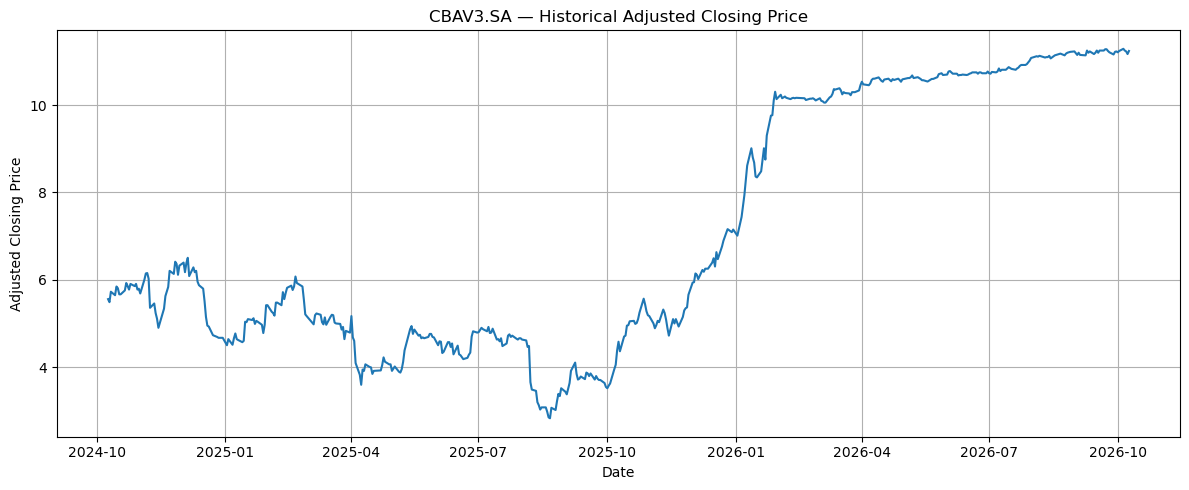

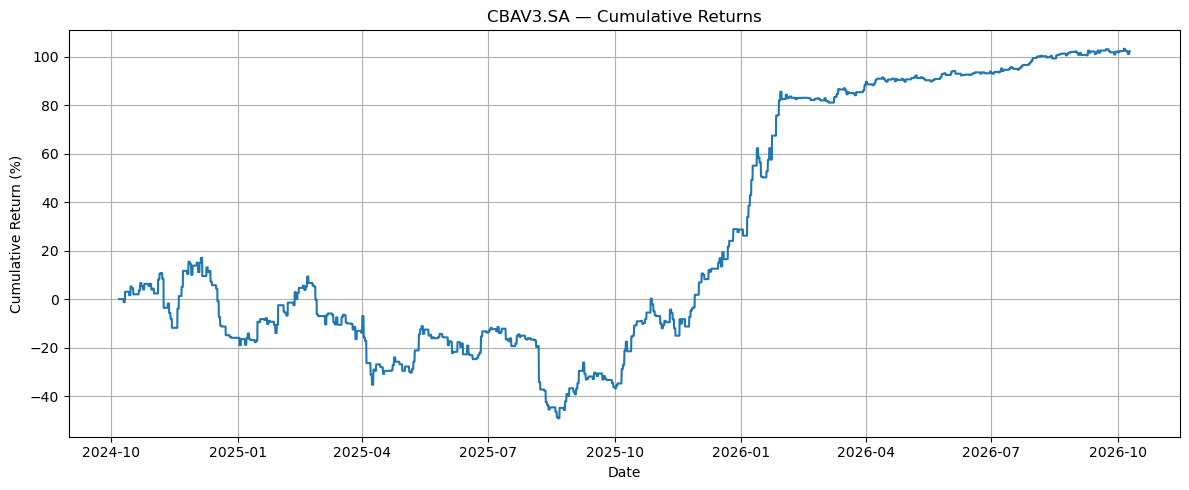

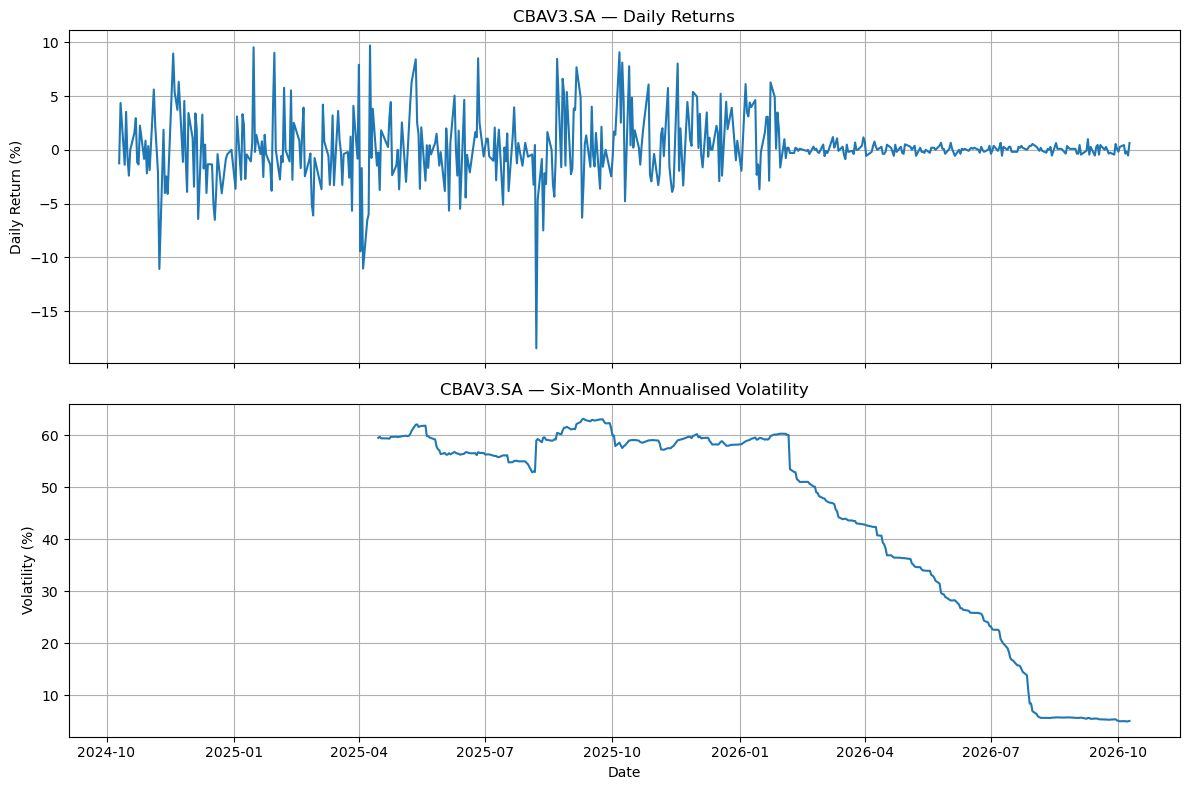

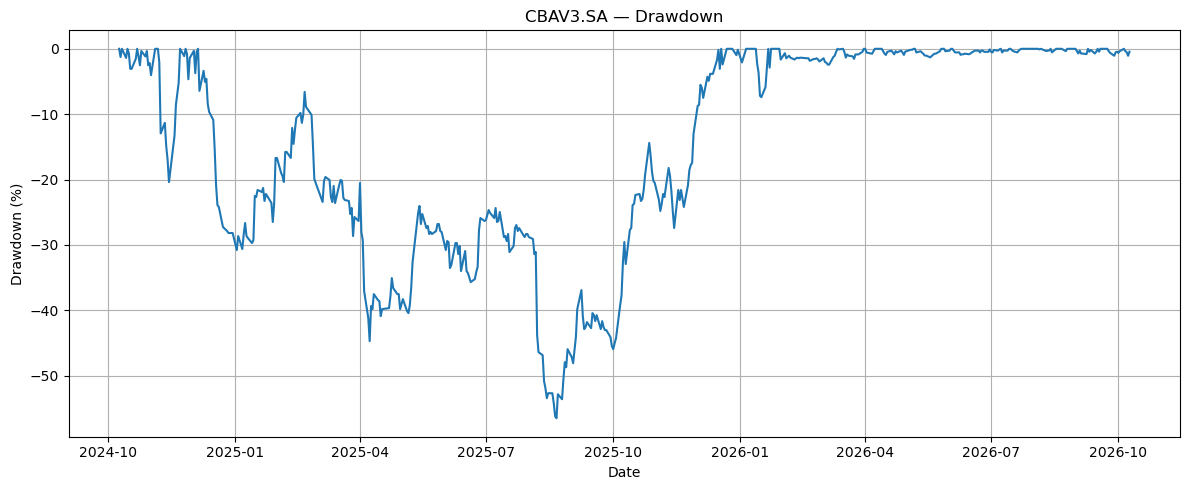

In [20]:
ticker = ranked_stocks.index[6]

plot_price(ticker)
plot_cumulative_returns(ticker)
plot_returns_and_volatility(ticker)
plot_drawdown(ticker)

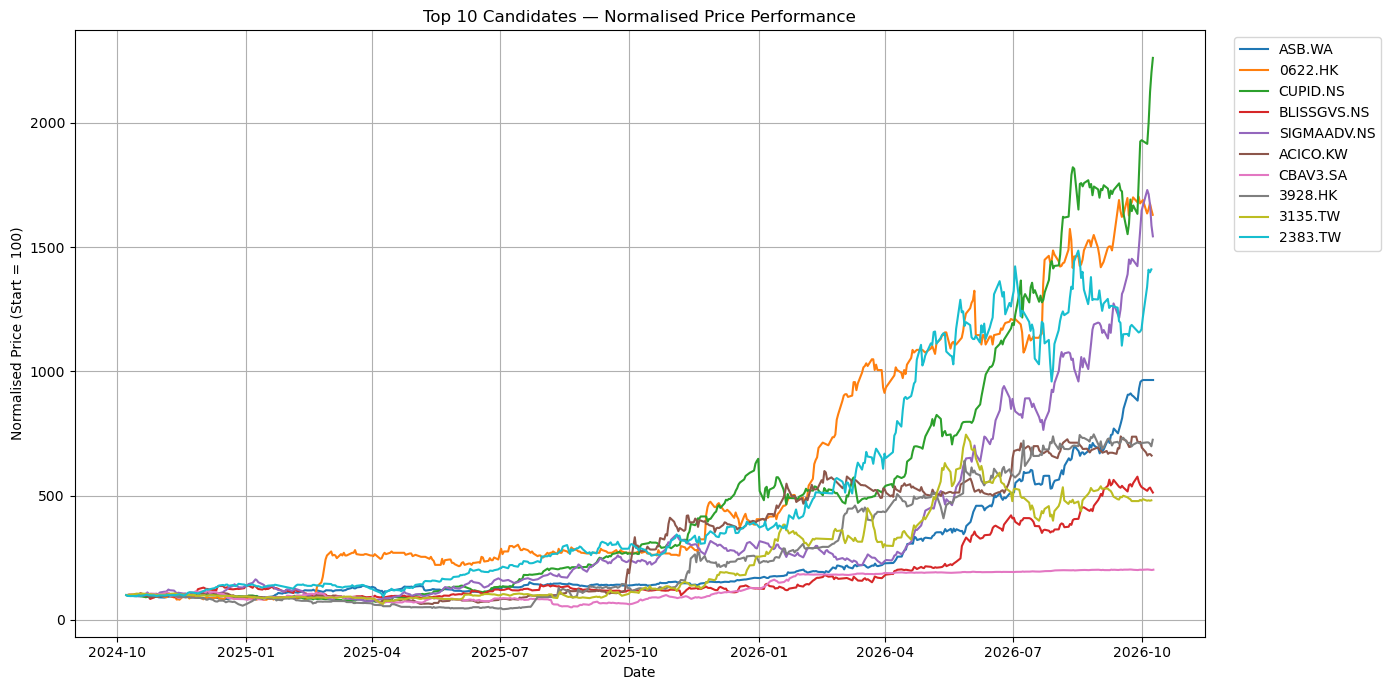

In [21]:
compare_shortlist(10)